# Answer the questions:

### Propose a new method to initialize cluster centroids for K-means. List the advantages and disadvantages of Forgy, Random Partition, and your own initializations.

k-means++, forgy очень рандомный, есть вероятность выбрать две близкие точки за центроиды, тогда все поломается
random partition - каждой точке рандомно назначается случайный кластер, и далее считается центроида по точкам из кластера, ваще тупой метод какой то, еще хуже форджи
к минс++ первую центроиду выбирает рандомно, потом след центроида выбирается с вероятностью, пропорциональной расстоянию до ближайшей цинтроиды (вторая центроида выберется просто дальняя от первой). ваще нормасный метод, решает проблему форджи


### Describe how you can use clustering to speed up the KNN model. Hint: what is kd-tree?

заранее разбить на кластеры, а кнн запускать уже только внутри кластеров

# Introduction: make all the preprocessing personnel from the previous lesson.

### Import libraries.


In [273]:
from random import gauss

import pandas as pd
import numpy as np
from collections import Counter
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.linear_model import Lasso
from sklearn.preprocessing import MinMaxScaler

### Read training and test examples

In [274]:
train = pd.read_csv('data/train.csv')
low = train['price'].quantile(0.01)
high = train['price'].quantile(0.99)
train = train.copy()[(train['price'] > low) & (train['price'] < high)].copy()
train

,Unnamed: 0,bathrooms,bedrooms,building_id,created,description,display_address,features,latitude,listing_id,longitude,manager_id,photos,price,street_address,interest_level
0,41416,2.0,2,f5e2cdb7a92059ee5e3dbd97b03f03ce,2016-04-26 05:43:01,"This beautiful, large 2 bedroom/2 bathroom apa...",E 18th St.,"['Pre-War', 'Laundry in Unit', 'Dishwasher', '...",40.7344,6927141,-73.9823,a2745e4ddab320a1fde31d4bbbdbba47,['https://photos.renthop.com/2/6927141_68978fd...,4295,336 E 18th St.,0
1,11754,1.0,1,ea0cb03ae8e72cb995207f0d1a9b8c14,2016-06-11 06:12:35,"Location, Location, Location!!! If the perfect...",South End Ave.,"['Swimming Pool', 'Doorman', 'Elevator', 'Fitn...",40.7109,7143353,-74.0165,2aa9bfa5f67ed9997ea341dee8a3a271,['https://photos.renthop.com/2/7143353_1d39b32...,2395,345 South End Ave.,0
2,31242,1.0,1,7a9ae106c9bf463c73963c4d40f332b9,2016-05-10 05:52:14,High floor one-bedroom home with northern expo...,East 86th Street,"['Doorman', 'Elevator', 'Fitness Center', 'Ter...",40.7779,6991420,-73.9525,7b159051957a4788a872ecb307613757,['https://photos.renthop.com/2/6991420_ff690f1...,3600,240 East 86th Street,0
3,24588,2.0,3,2ac8c0b8e176dba6b86606e35b1b463d,2016-05-27 05:35:25,"Brand New, gut renovated, 3 bedroom apartment ...","Midtown, Kips Bay","['Common Outdoor Space', 'Laundry In Unit', 'C...",40.7434,7076511,-73.9746,77e00a2ddf0c8b994f256db73f72cffd,['https://photos.renthop.com/2/7076511_bcdb48d...,6200,377 East 33rd Street,1
4,32205,1.0,2,0,2016-05-27 05:21:25,Updated Two Bedroom One Bath Amenities Include...,76 West 85th Street,"['Laundry in Building', 'Dishwasher', 'Hardwoo...",40.7855,7076348,-73.9725,cbcdd7b2f2edb96d73cae07bb25704f8,['https://photos.renthop.com/2/7076348_e6cdccb...,3850,76 West 85th Street,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
36252,23261,1.0,2,9174b75c0cd978eb0e5aa93afbad754b,2016-05-20 06:29:00,STUNNING FLEX 2 BEDROOM APARTMENT LOCATED IN M...,East 33rd Street,"['Doorman', 'Elevator', 'Dishwasher', 'Hardwoo...",40.7456,7044399,-73.9797,eb5a6c4c2eb6f3e2a085c477afd5a815,['https://photos.renthop.com/2/7044399_1bf3ebe...,2850,141 East 33rd Street,2
36253,3206,1.0,3,80a120d6bc3aba97f40fee8c2204524b,2016-06-16 05:51:21,"Location, Location, Location!!! If the perfect...",Water Street,"['Roof Deck', 'Doorman', 'Elevator', 'Laundry ...",40.7073,7170259,-74.0046,2aa9bfa5f67ed9997ea341dee8a3a271,['https://photos.renthop.com/2/7170259_242c629...,3200,200 Water Street,1
36254,14981,1.0,0,b1daadbd01eda6f354e8c91180c206df,2016-06-21 06:22:10,Gorgeous junior one bedroom located in...,Fort Washington Avenue,"['Elevator', 'Cats Allowed', 'Dogs Allowed']",40.8380,7193061,-73.9438,e6472c7237327dd3903b3d6f6a94515a,['https://photos.renthop.com/2/7193061_6ea82f5...,1750,80 Fort Washington Avenue,0
36255,47605,1.0,1,0935cc25b8b93f78144e87604bf8e93a,2016-04-04 11:36:23,Extra large 1 bedroom/ 1 bathroom unit is avai...,22-43 28th street,"['Common Outdoor Space', 'Cats Allowed', 'Priv...",40.7762,6822127,-73.9133,2a469a9088ebd5a29e8a210a14e2cecf,['https://photos.renthop.com/2/6822127_5b07d8c...,1995,22-43 28th street,1


In [275]:
train['features'] = (train['features'].astype(str).str.replace('[', '', regex=False).str.replace(']', '', regex=False).str.replace("'", "", regex=False).str.replace('"', '', regex=False).str.replace(' ', '', regex=False))
train['features']

0        Pre-War,LaundryinUnit,Dishwasher,HardwoodFloor...
1        SwimmingPool,Doorman,Elevator,FitnessCenter,La...
2        Doorman,Elevator,FitnessCenter,Terrace,Laundry...
3        CommonOutdoorSpace,LaundryInUnit,CatsAllowed,D...
4        LaundryinBuilding,Dishwasher,HardwoodFloors,Ca...
                               ...                        
36252     Doorman,Elevator,Dishwasher,HardwoodFloors,NoFee
36253    RoofDeck,Doorman,Elevator,LaundryinUnit,HighSp...
36254                     Elevator,CatsAllowed,DogsAllowed
36255    CommonOutdoorSpace,CatsAllowed,PrivateOutdoorS...
36256                              CatsAllowed,DogsAllowed
Name: features, Length: 35419, dtype: object

### Create features: 'Elevator', 'HardwoodFloors', 'CatsAllowed', 'DogsAllowed', 'Doorman', 'Dishwasher', 'NoFee', 'LaundryinBuilding', 'FitnessCenter', 'Pre-War', 'LaundryinUnit', 'RoofDeck', 'OutdoorSpace', 'DiningRoom', 'HighSpeedInternet', 'Balcony', 'SwimmingPool', 'LaundryInBuilding', 'NewConstruction', 'Terrace'.

In [276]:
big_list = []
for i, row in train.iterrows():
    for i in row['features'].split(','):
        if i.strip():
            big_list.append(i.strip())
big_list

['Pre-War',
 'LaundryinUnit',
 'Dishwasher',
 'HardwoodFloors',
 'NoFee',
 'DogsAllowed',
 'CatsAllowed',
 'SwimmingPool',
 'Doorman',
 'Elevator',
 'FitnessCenter',
 'LaundryinBuilding',
 'LaundryinUnit',
 'Dishwasher',
 'HardwoodFloors',
 'NoFee',
 'Doorman',
 'Elevator',
 'FitnessCenter',
 'Terrace',
 'LaundryinBuilding',
 'LaundryinUnit',
 'Dishwasher',
 'HardwoodFloors',
 'NoFee',
 'DogsAllowed',
 'CatsAllowed',
 'CommonOutdoorSpace',
 'LaundryInUnit',
 'CatsAllowed',
 'DogsAllowed',
 'NoFee',
 'Doorman',
 'Elevator',
 'FitnessCenter',
 'LaundryInBuilding',
 'LaundryinBuilding',
 'HardwoodFloors',
 'NewConstruction',
 'LaundryinUnit',
 'RoofDeck',
 'Dishwasher',
 'LaundryinBuilding',
 'Dishwasher',
 'HardwoodFloors',
 'CatsAllowed',
 'LaundryinUnit',
 'Dishwasher',
 'HardwoodFloors',
 'Pre-War',
 'Dishwasher',
 'HardwoodFloors',
 'Elevator',
 'Furnished',
 'HardwoodFloors',
 'Balcony',
 'Doorman',
 'Elevator',
 'Garden/Patio',
 'LaundryinBuilding',
 'LaundryinUnit',
 'HardwoodFloo

In [277]:
counts = Counter(big_list)
most_common_features = counts.most_common(20)
most_common_features

[('Elevator', 18658),
 ('HardwoodFloors', 16992),
 ('CatsAllowed', 16855),
 ('DogsAllowed', 15779),
 ('Doorman', 15033),
 ('Dishwasher', 14748),
 ('NoFee', 13119),
 ('LaundryinBuilding', 11855),
 ('FitnessCenter', 9506),
 ('Pre-War', 6607),
 ('LaundryinUnit', 6060),
 ('RoofDeck', 4693),
 ('OutdoorSpace', 3712),
 ('DiningRoom', 3490),
 ('HighSpeedInternet', 3088),
 ('Balcony', 2121),
 ('SwimmingPool', 1940),
 ('LaundryInBuilding', 1919),
 ('NewConstruction', 1804),
 ('Terrace', 1531)]

In [278]:
features = []
for i in most_common_features:
    features.append(i[0])
features_series = pd.Series(features, name = 'features')
features_series

0              Elevator
1        HardwoodFloors
2           CatsAllowed
3           DogsAllowed
4               Doorman
5            Dishwasher
6                 NoFee
7     LaundryinBuilding
8         FitnessCenter
9               Pre-War
10        LaundryinUnit
11             RoofDeck
12         OutdoorSpace
13           DiningRoom
14    HighSpeedInternet
15              Balcony
16         SwimmingPool
17    LaundryInBuilding
18      NewConstruction
19              Terrace
Name: features, dtype: object

In [279]:
y_train = train['price']
train = train[['bathrooms', 'bedrooms', 'longitude', 'latitude', 'interest_level', 'features']]
train
mega_df = train['features'].str.get_dummies(sep=',')[features]
mega_df

,Elevator,HardwoodFloors,CatsAllowed,DogsAllowed,Doorman,Dishwasher,NoFee,LaundryinBuilding,FitnessCenter,Pre-War,LaundryinUnit,RoofDeck,OutdoorSpace,DiningRoom,HighSpeedInternet,Balcony,SwimmingPool,LaundryInBuilding,NewConstruction,Terrace
0,0,1,1,1,0,1,1,0,0,1,1,0,0,0,0,0,0,0,0,0
1,1,1,0,0,1,1,1,1,1,0,1,0,0,0,0,0,1,0,0,0
2,1,1,1,1,1,1,1,1,1,0,1,0,0,0,0,0,0,0,0,1
3,1,1,1,1,1,1,1,1,1,0,1,1,0,0,0,0,0,1,1,0
4,0,1,1,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
36252,1,1,0,0,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0
36253,1,1,0,0,1,1,1,0,0,0,1,1,0,0,1,0,0,0,0,0
36254,1,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
36255,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [280]:
train = train.drop(columns='features')
X_train = pd.concat([train, mega_df], axis=1)
X_train, X_test, y_train, y_test = train_test_split(X_train, y_train, test_size=0.2, random_state=21)
feature_names = X_train.columns

# Implement the next method:

### K-means algorithm.


In [281]:
class myKMeans:
    def __init__(self, k_clusters, max_iter, random_state, epsilon = 0.0000001):
        self.k_clusters = k_clusters
        self.max_iter = max_iter
        self.random_state = random_state
        self.epsilon = epsilon

    def _assign(self, X, labels):
        for i in range(len(X)):
            dists = []
            for k in self.centroids:
                dists.append(np.linalg.norm(X[i] - k))
            label = np.argmin(dists)
            labels.append(label)
        return labels


    def fit(self, X):
        X = np.array(X)
        rng = np.random.default_rng(self.random_state)
        idx = rng.choice(X.shape[0], self.k_clusters, replace=False)
        self.centroids = X[idx]
        for _ in range(self.max_iter):
            labels = []
            labels = np.array(self._assign(X, labels))
            old_centroids = self.centroids.copy()
            for k in range(self.k_clusters):
                mask = labels == k
                k_cluster = X[mask]
                mean = np.mean(k_cluster, axis=0)
                self.centroids[k] = mean
            if np.linalg.norm(old_centroids - self.centroids) < self.epsilon:
                break
        final_labels = []
        self.labels = np.array(self._assign(X, final_labels))
        self.distortion = np.sum(np.square(X - self.centroids[self.labels]))

    def predict(self, X):
        X = np.array(X)
        labels = []
        pred = np.array(self._assign(X, labels))
        return pred

### Fit cluster algorithm with 30 clusters on 'longitude' and 'latitude' features, make prediction for training and test samples.

In [282]:
train_features = X_train[['longitude', 'latitude']]
myKM = myKMeans(k_clusters=30, max_iter=100, random_state=21)
myKM.fit(train_features)
pred_train = myKM.predict(X_train[['longitude', 'latitude']])
pred_test = myKM.predict(X_test[['longitude', 'latitude']])

In [283]:
np.array_equal(pred_train, myKM.labels)

True

### Compute Silhouette score and Distortion.

In [284]:
silh = silhouette_score(X_test[['longitude', 'latitude']], labels=pred_test, sample_size=5000)
silh

0.42024729787567994

In [285]:
distortion = myKM.distortion
distortion

np.float64(10.990043632648064)

### Draw result with scatterplot, try to analyze it.

(40.6, 40.9)

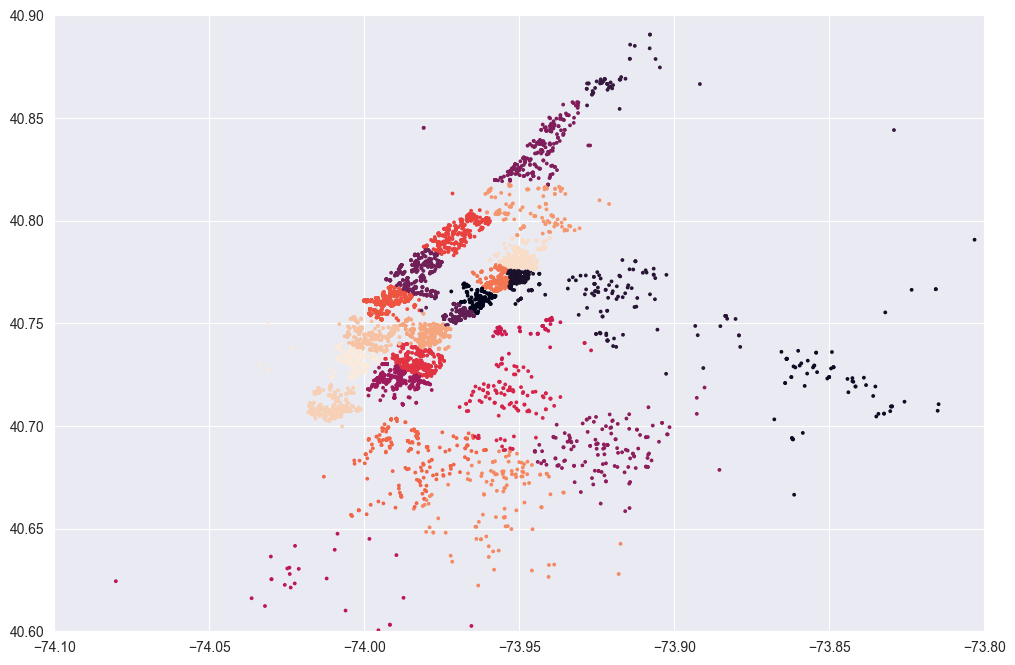

In [286]:
plt.figure(figsize=(12, 8))
plt.scatter(c=pred_test, s = 3, x=X_test['longitude'], y=X_test['latitude'])
plt.xlim(-74.1, -73.8)
plt.ylim(40.6, 40.9)


### Add the label of the cluster as a feature in the Lasso Regression with MinMaxScaller.


In [287]:
X_train['labels'] = pred_train
X_test['labels'] = pred_test

In [288]:
new_X_train = X_train.copy()
new_X_test = X_test.copy()
X_train.drop(columns='labels', inplace=True)
X_test.drop(columns='labels', inplace=True)

In [289]:
feature_names = new_X_train.columns

In [291]:
scaler = MinMaxScaler()
new_X_train = scaler.fit_transform(new_X_train)
new_X_test = scaler.transform(new_X_test)
lasso = Lasso(random_state=21, fit_intercept=True)
lasso.fit(new_X_train, y_train)
preds = lasso.predict(new_X_test)

### Print the feature importance as the feature weight from the Lasso.


In [292]:
feature_imp = pd.DataFrame({'feature': feature_names, 'weights': abs(lasso.coef_)})
feature_imp

,feature,weights
0,bathrooms,11557.918067
1,bedrooms,2983.431905
2,longitude,0.000000
3,latitude,0.000000
4,interest_level,782.416992
5,Elevator,183.496137
6,HardwoodFloors,100.502954
7,CatsAllowed,0.000000
8,DogsAllowed,84.133195
9,Doorman,521.085375


In [293]:
sorted_imp = feature_imp.sort_values(by='weights', ascending=False)
sorted_imp

,feature,weights
0,bathrooms,11557.918067
1,bedrooms,2983.431905
4,interest_level,782.416992
9,Doorman,521.085375
25,labels,422.287432
15,LaundryinUnit,353.199870
19,HighSpeedInternet,202.327048
5,Elevator,183.496137
22,LaundryInBuilding,168.647318
13,FitnessCenter,165.535263


### Import K-means from sklearn and compare results.


In [294]:
km = KMeans(n_clusters=30, max_iter=100, random_state=21)
km.fit(X_train[['longitude', 'latitude']])
preds = km.predict(X_test[['longitude', 'latitude']])


In [295]:
silh = silhouette_score(X_test[['longitude', 'latitude']], labels=pred_test, sample_size=5000)
silh
dist = km.inertia_
dist

3.3950811033810635

# Do the same steps, but with the DBScan algorithm (try different parameters for better Lasso model quality).

In [296]:
class myDBSCAN:
    def __init__(self, eps, min_samples):
        self.eps = eps
        self.min_samples = min_samples

    def fit(self, X):
        X = np.array(X)
        all_neighbors = []
        is_core = []
        for i in range(len(X)):
            count = 0
            neighbors = []
            for j in range(len(X)):
                if np.linalg.norm(X[i] - X[j]) <= self.eps:
                    count += 1
                    neighbors.append(j)
            if count >= self.min_samples:
                is_core.append(True)
                all_neighbors.append(neighbors)
            else:
                is_core.append(False)
                all_neighbors.append(neighbors)
        labels = [-1] * len(X)
        cluster_id = 0
        for i in range(len(X)):
            if not is_core[i] or labels[i] != -1:
                continue
            labels[i] = cluster_id
            queue = [i]
            while queue:
                q = queue.pop()
                if is_core[q]:
                    for r in all_neighbors[q]:
                        if labels[r] == -1:
                            labels[r] = cluster_id
                            queue.append(r)
            cluster_id += 1
        self.labels = np.array(labels)


### Fit cluster algorithm with 30 clusters on 'longitude' and 'latitude' features, make prediction for training and test samples.

In [297]:
dbs = myDBSCAN(eps=0.001, min_samples=7)
dbs.fit(X_test[['longitude', 'latitude']])

In [298]:
mask = dbs.labels != -1
silh = silhouette_score(X_test[['longitude', 'latitude']][mask], labels=dbs.labels[mask], sample_size=5000)
silh

0.3743218450661241

In [299]:
def distortion_dbs(X, labels):
    X = np.array(X)
    total = 0
    for c in set(labels):
        if c == -1:
            continue
        members = [X[i] for i in range(len(X)) if labels[i] == c]
        mu = sum(members) / len(members)
        for x in members:
            total += np.sum((x - mu) ** 2)
    return total

In [300]:
distortion = distortion_dbs(X_test[['longitude', 'latitude']], dbs.labels)
distortion

np.float64(0.031364542785844954)

(40.6, 40.9)

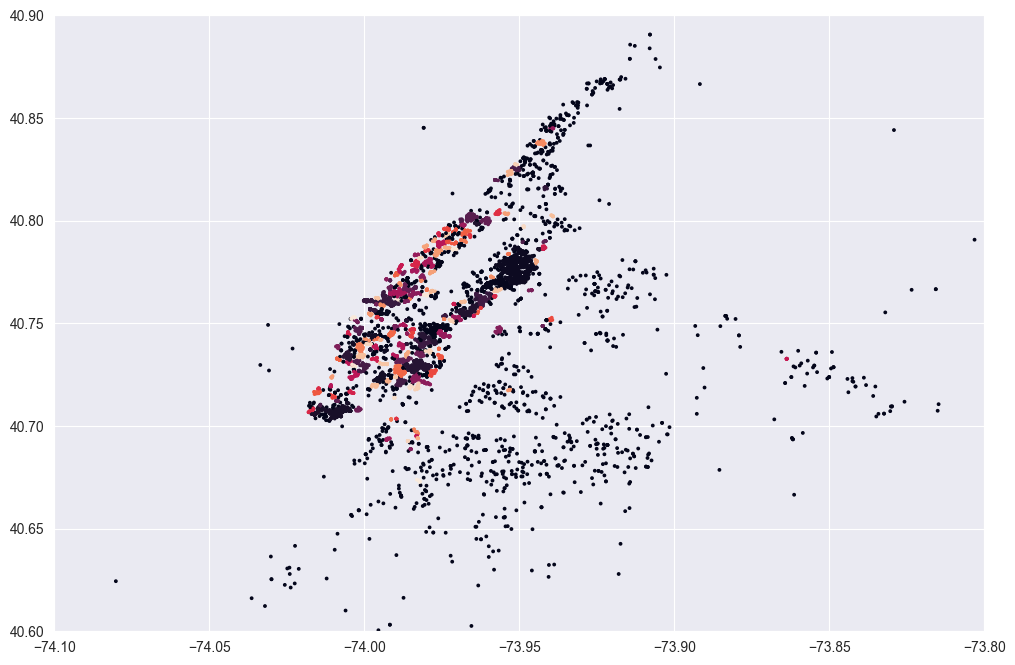

In [301]:
plt.figure(figsize=(12, 8))
plt.scatter(c=dbs.labels, s = 3, x=X_test['longitude'], y=X_test['latitude'])
plt.xlim(-74.1, -73.8)
plt.ylim(40.6, 40.9)


In [302]:
X_test['labels'] = dbs.labels

In [303]:
new_X_test = X_test.copy()
X_test.drop(columns='labels', inplace=True)

In [304]:
feature_names = new_X_test.columns
feature_names

Index(['bathrooms', 'bedrooms', 'longitude', 'latitude', 'interest_level',
       'Elevator', 'HardwoodFloors', 'CatsAllowed', 'DogsAllowed', 'Doorman',
       'Dishwasher', 'NoFee', 'LaundryinBuilding', 'FitnessCenter', 'Pre-War',
       'LaundryinUnit', 'RoofDeck', 'OutdoorSpace', 'DiningRoom',
       'HighSpeedInternet', 'Balcony', 'SwimmingPool', 'LaundryInBuilding',
       'NewConstruction', 'Terrace', 'labels'],
      dtype='object')

In [305]:
scaler = MinMaxScaler()
new_X_train = scaler.fit_transform(new_X_train)
new_X_test = scaler.transform(new_X_test)
lasso = Lasso(random_state=21, fit_intercept=True)
lasso.fit(new_X_test, y_test)
preds = lasso.predict(new_X_test)

C:\Users\130\school_21_ds_1\.venv\Lib\site-packages\sklearn\utils\validation.py:2684: UserWarning: X has feature names, but MinMaxScaler was fitted without feature names
  warnings.warn(


In [306]:
feature_imp = pd.DataFrame({'feature': feature_names, 'weights': abs(lasso.coef_)})
feature_imp

,feature,weights
0,bathrooms,1249.376876
1,bedrooms,466.528105
2,longitude,473.503176
3,latitude,871.744664
4,interest_level,355.282411
5,Elevator,217.051657
6,HardwoodFloors,166.222616
7,CatsAllowed,24.853819
8,DogsAllowed,67.203933
9,Doorman,452.888036


In [307]:
skDB = DBSCAN(eps=0.001, min_samples=7)
skDB_labels = skDB.fit_predict(X_test[['longitude', 'latitude']])

In [308]:
silhouette_score(X_test[['longitude', 'latitude']], labels=skDB_labels, sample_size=5000)

0.0626305930580913

In [309]:
distortion_dbs(X_test[['longitude', 'latitude']], skDB_labels)

np.float64(0.031364542785844954)

# Next, do the same steps as before, but the implementation of the AgglomerativeClustering algorithm is not mandatory for you, you can import it from sklearn.

In [310]:
aggcl = AgglomerativeClustering(n_clusters=30)
agg_pred_train = aggcl.fit_predict(X_train[['longitude', 'latitude']])

In [311]:
agg_pred_test = aggcl.fit_predict(X_test[['longitude', 'latitude']])

In [312]:
silhouette_score(X_test[['longitude', 'latitude']], labels=agg_pred_test, sample_size=5000)

0.45263020065778536

(40.6, 40.9)

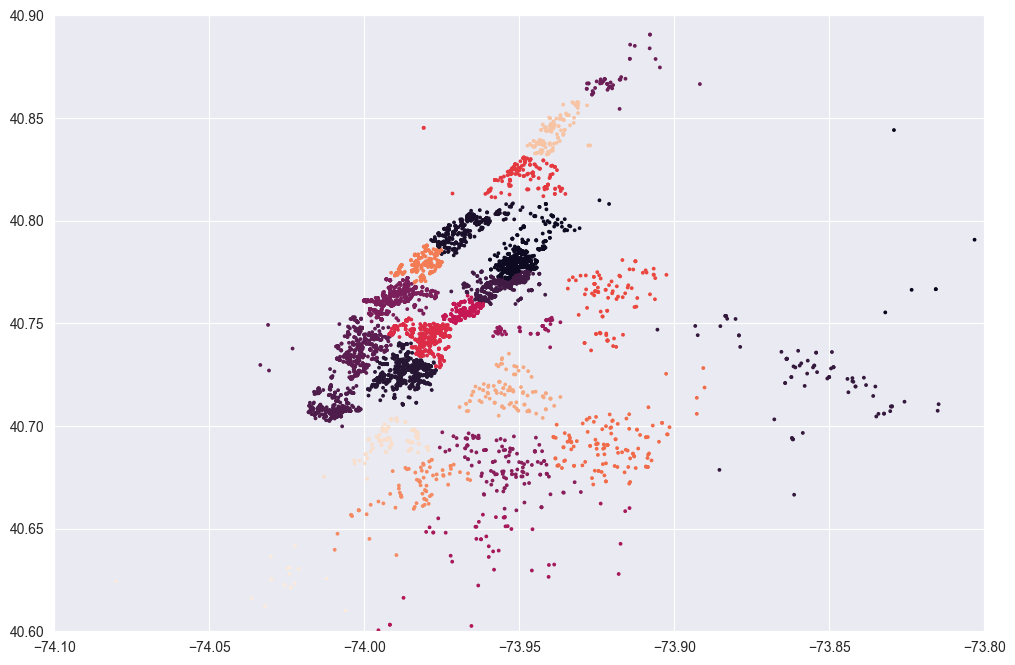

In [313]:
plt.figure(figsize=(12, 8))
plt.scatter(c=agg_pred_test, s = 3, x=X_test['longitude'], y=X_test['latitude'])
plt.xlim(-74.1, -73.8)
plt.ylim(40.6, 40.9)

In [314]:
X_train['labels'] = agg_pred_train
X_test['labels'] = agg_pred_test

In [315]:
new_X_train = X_train.copy()
new_X_test = X_test.copy()
X_train.drop(columns='labels', inplace=True)
X_test.drop(columns='labels', inplace=True)

In [316]:
feature_names = new_X_train.columns

In [317]:
scaler = MinMaxScaler()
new_X_train = scaler.fit_transform(new_X_train)
new_X_test = scaler.transform(new_X_test)
lasso = Lasso(random_state=21, fit_intercept=True)
lasso.fit(new_X_train, y_train)
preds = lasso.predict(new_X_test)

In [318]:
feature_imp = pd.DataFrame({'feature': feature_names, 'weights': abs(lasso.coef_)})
sorted_imp = feature_imp.sort_values(by='weights', ascending=False)
sorted_imp

,feature,weights
0,bathrooms,11595.531830
1,bedrooms,2975.890301
4,interest_level,795.763893
9,Doorman,524.989623
15,LaundryinUnit,361.226263
25,labels,345.261441
19,HighSpeedInternet,218.050125
13,FitnessCenter,196.182536
5,Elevator,184.596995
12,LaundryinBuilding,161.078020


# Do the same for the Gaussian Mixture algorithm.


In [319]:
gauss = GaussianMixture(n_components=30, random_state=21)
gauss_pred_train = gauss.fit_predict(X_train[['longitude', 'latitude']])
gauss_pred_test = gauss.fit_predict(X_test[['longitude', 'latitude']])

In [320]:
silhouette_score(X_train[['longitude', 'latitude']], labels=gauss_pred_train, sample_size=5000)

0.4300638939053395

In [321]:
silhouette_score(X_test[['longitude', 'latitude']], labels=gauss_pred_test, sample_size=5000)

0.3645375343951542

(40.6, 40.9)

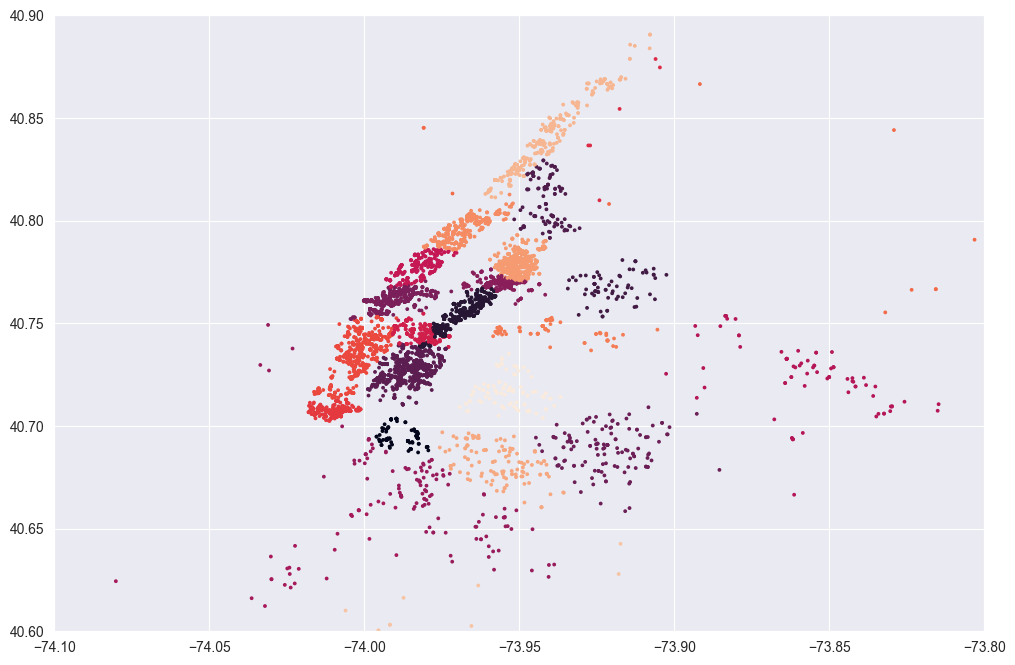

In [322]:
plt.figure(figsize=(12, 8))
plt.scatter(c=gauss_pred_test, s = 3, x=X_test['longitude'], y=X_test['latitude'])
plt.xlim(-74.1, -73.8)
plt.ylim(40.6, 40.9)

In [323]:
X_train['labels'] = gauss_pred_train
X_test['labels'] = gauss_pred_test

In [324]:
new_X_train = X_train.copy()
new_X_test = X_test.copy()
X_train.drop(columns='labels', inplace=True)
X_test.drop(columns='labels', inplace=True)

In [325]:
feature_names = new_X_train.columns

In [326]:
scaler = MinMaxScaler()
new_X_train = scaler.fit_transform(new_X_train)
new_X_test = scaler.transform(new_X_test)
lasso = Lasso(random_state=21, fit_intercept=True)
lasso.fit(new_X_train, y_train)
preds = lasso.predict(new_X_test)

In [327]:
feature_imp = pd.DataFrame({'feature': feature_names, 'weights': abs(lasso.coef_)})
sorted_imp = feature_imp.sort_values(by='weights', ascending=False)
sorted_imp

,feature,weights
0,bathrooms,11488.757254
1,bedrooms,2982.187022
4,interest_level,786.130801
9,Doorman,531.203662
15,LaundryinUnit,363.286700
19,HighSpeedInternet,208.382808
13,FitnessCenter,200.476535
5,Elevator,191.079930
12,LaundryinBuilding,164.803843
22,LaundryInBuilding,155.050751


# Compare the results with the complexity, speed and accuracy of these methods.


Самый быстрый: K-Means

Лучший по качеству: DBSCAN